In [1]:
import matplotlib.pyplot as plt
import torch

In [ ]:
replace_with_average_seq = torch.load("accuracy/accuracy_list_seq_Average.pt")
replace_with_zero_seq = torch.load("accuracy/accuracy_list_seq_zero.pt")
replace_with_zipit_seq = torch.load("accuracy/accuracy_list_seq_ZipIt.pt")
replace_with_proj_seq = torch.load("accuracy/accuracy_list_seq_Projection.pt")
replace_with_best_seq = torch.load("accuracy/accuracy_list_seq_Best.pt")

replace_with_average_single = torch.load("accuracy/accuracy_list_single_Average.pt")
replace_with_zero_single = torch.load("accuracy/accuracy_list_single_zero.pt")
replace_with_zipit_single = torch.load("accuracy/accuracy_list_single_ZipIt.pt")
replace_with_proj_single = torch.load("accuracy/accuracy_list_single_Projection.pt")
replace_with_best_single = torch.load("accuracy/accuracy_list_single_Best.pt")

In [3]:
def draw(data):
    data_keys = list(data.keys())
    plt.figure(figsize=(20, 20))
    plt.subplot(2, 2, 1)

    for name, xs in data.items():
        plt.plot(xs[0], label=name)
    plt.legend()
    plt.xlabel("Number of changed layers")
    plt.ylabel("Accuracy")
    plt.title("Accuracy after changing some layer (from best to worst)")

    plt.subplot(2, 2, 2)

    colors = ['r', 'g', 'b', 'y', 'purple']
    vp = plt.violinplot([data[key][0] for key in data_keys])
    for i, body in enumerate(vp['bodies']):
        body.set_facecolor(colors[i])
    plt.legend(data_keys)
    plt.ylim((0, 1.1))
    plt.xlabel("Number of changed layers")
    plt.ylabel("Accuracy")
    plt.title("Accuracy after changing some layer (from best to worst)")

    plt.subplot(2, 2, 3)

    for name, xs in data.items():
        plt.plot(xs[1], label=name)
    plt.legend()
    plt.xlabel("Changed layers")
    plt.ylabel("Accuracy")
    plt.title("Accuracy after changing one layer")

    plt.subplot(2, 2, 4)

    vp = plt.violinplot([data[key][1] for key in data_keys])
    for i, body in enumerate(vp['bodies']):
        body.set_facecolor(colors[i])
    plt.legend(data_keys)
    plt.ylim((0, 1.1))
    plt.ylabel("Accuracy")
    plt.title("Accuracy after changing one layer")

    plt.show()

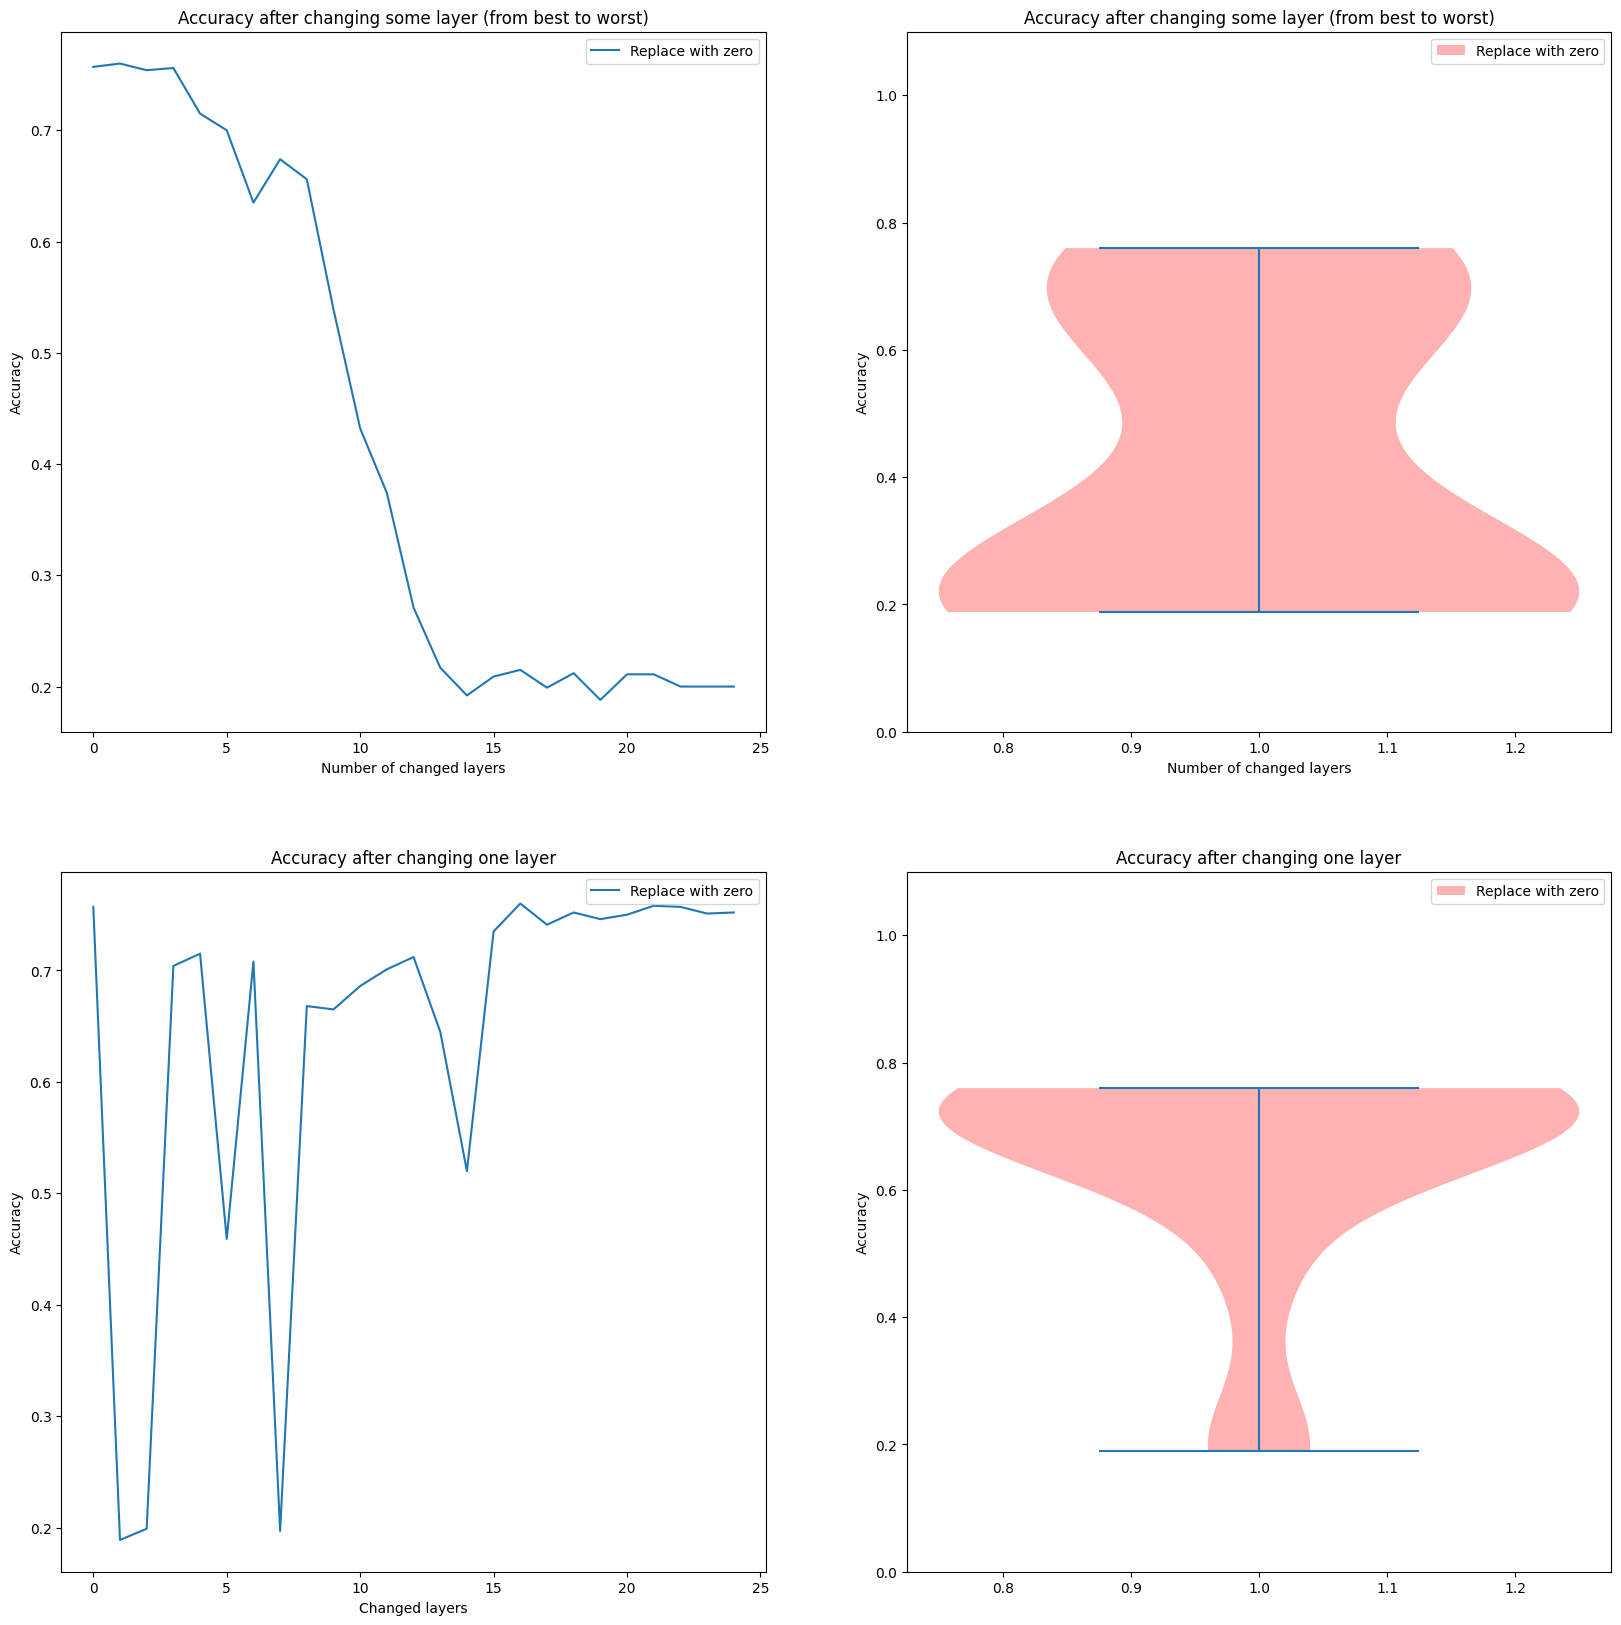

In [4]:
data = {
    # "Replace with average": [replace_with_average_seq, replace_with_average_single],
    "Replace with zero": [replace_with_zero_seq, replace_with_zero_single],
    # "Replace with ZipIt": [replace_with_zipit_seq, replace_with_zipit_single],
    # "Replace with proj": [replace_with_proj_seq, replace_with_proj_single],
    # "Replace with best": [replace_with_best_seq, replace_with_best_single],
}
draw(data)

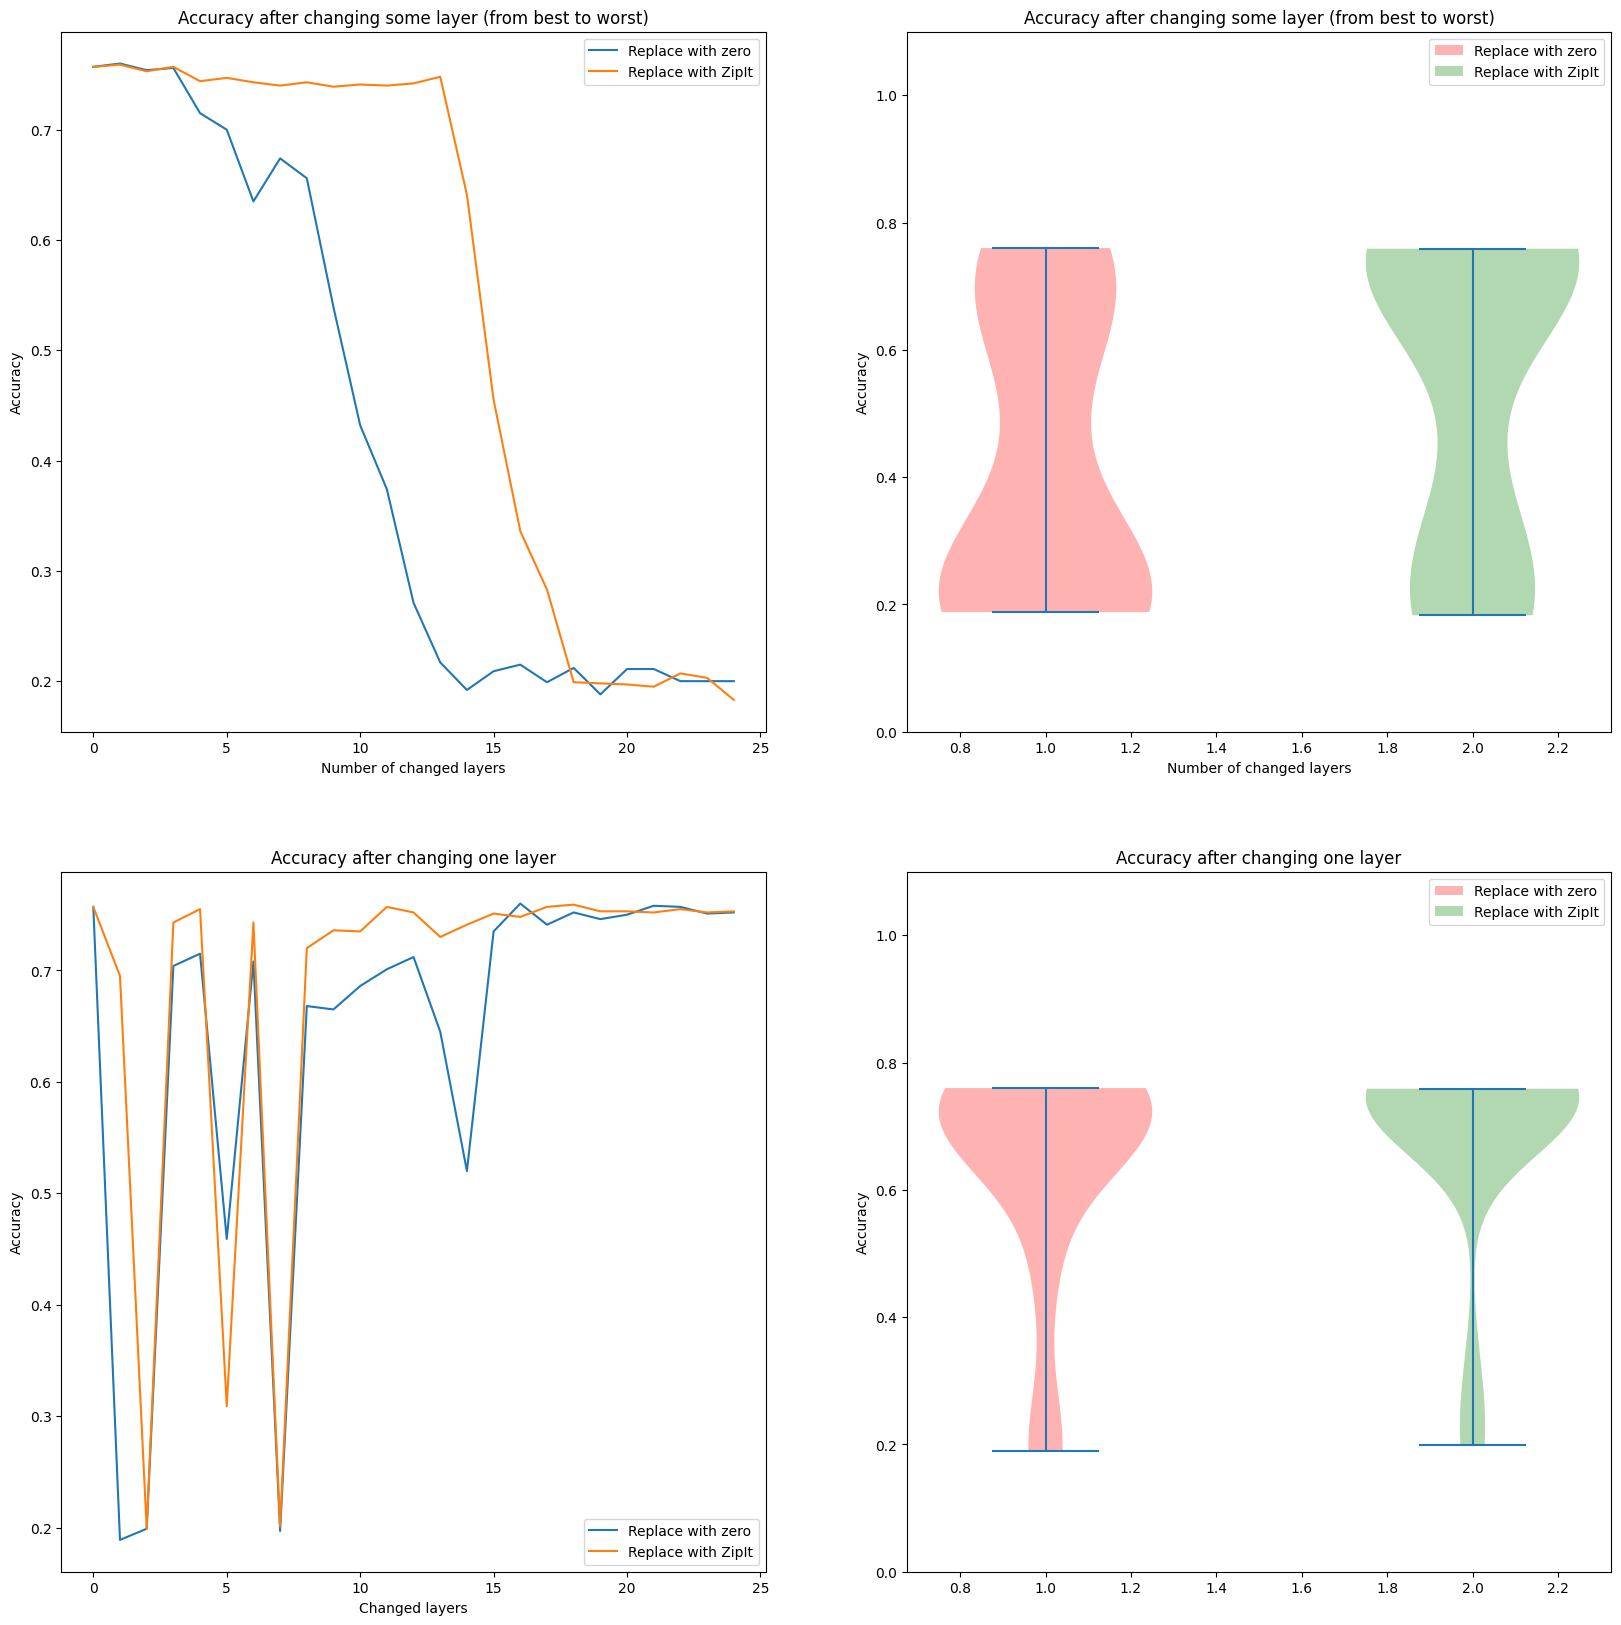

In [5]:
data = {
    # "Replace with average": [replace_with_average_seq, replace_with_average_single],
    "Replace with zero": [replace_with_zero_seq, replace_with_zero_single],
    "Replace with ZipIt": [replace_with_zipit_seq, replace_with_zipit_single],
    # "Replace with proj": [replace_with_proj_seq, replace_with_proj_single],
    # "Replace with best": [replace_with_best_seq, replace_with_best_single],
}
draw(data)

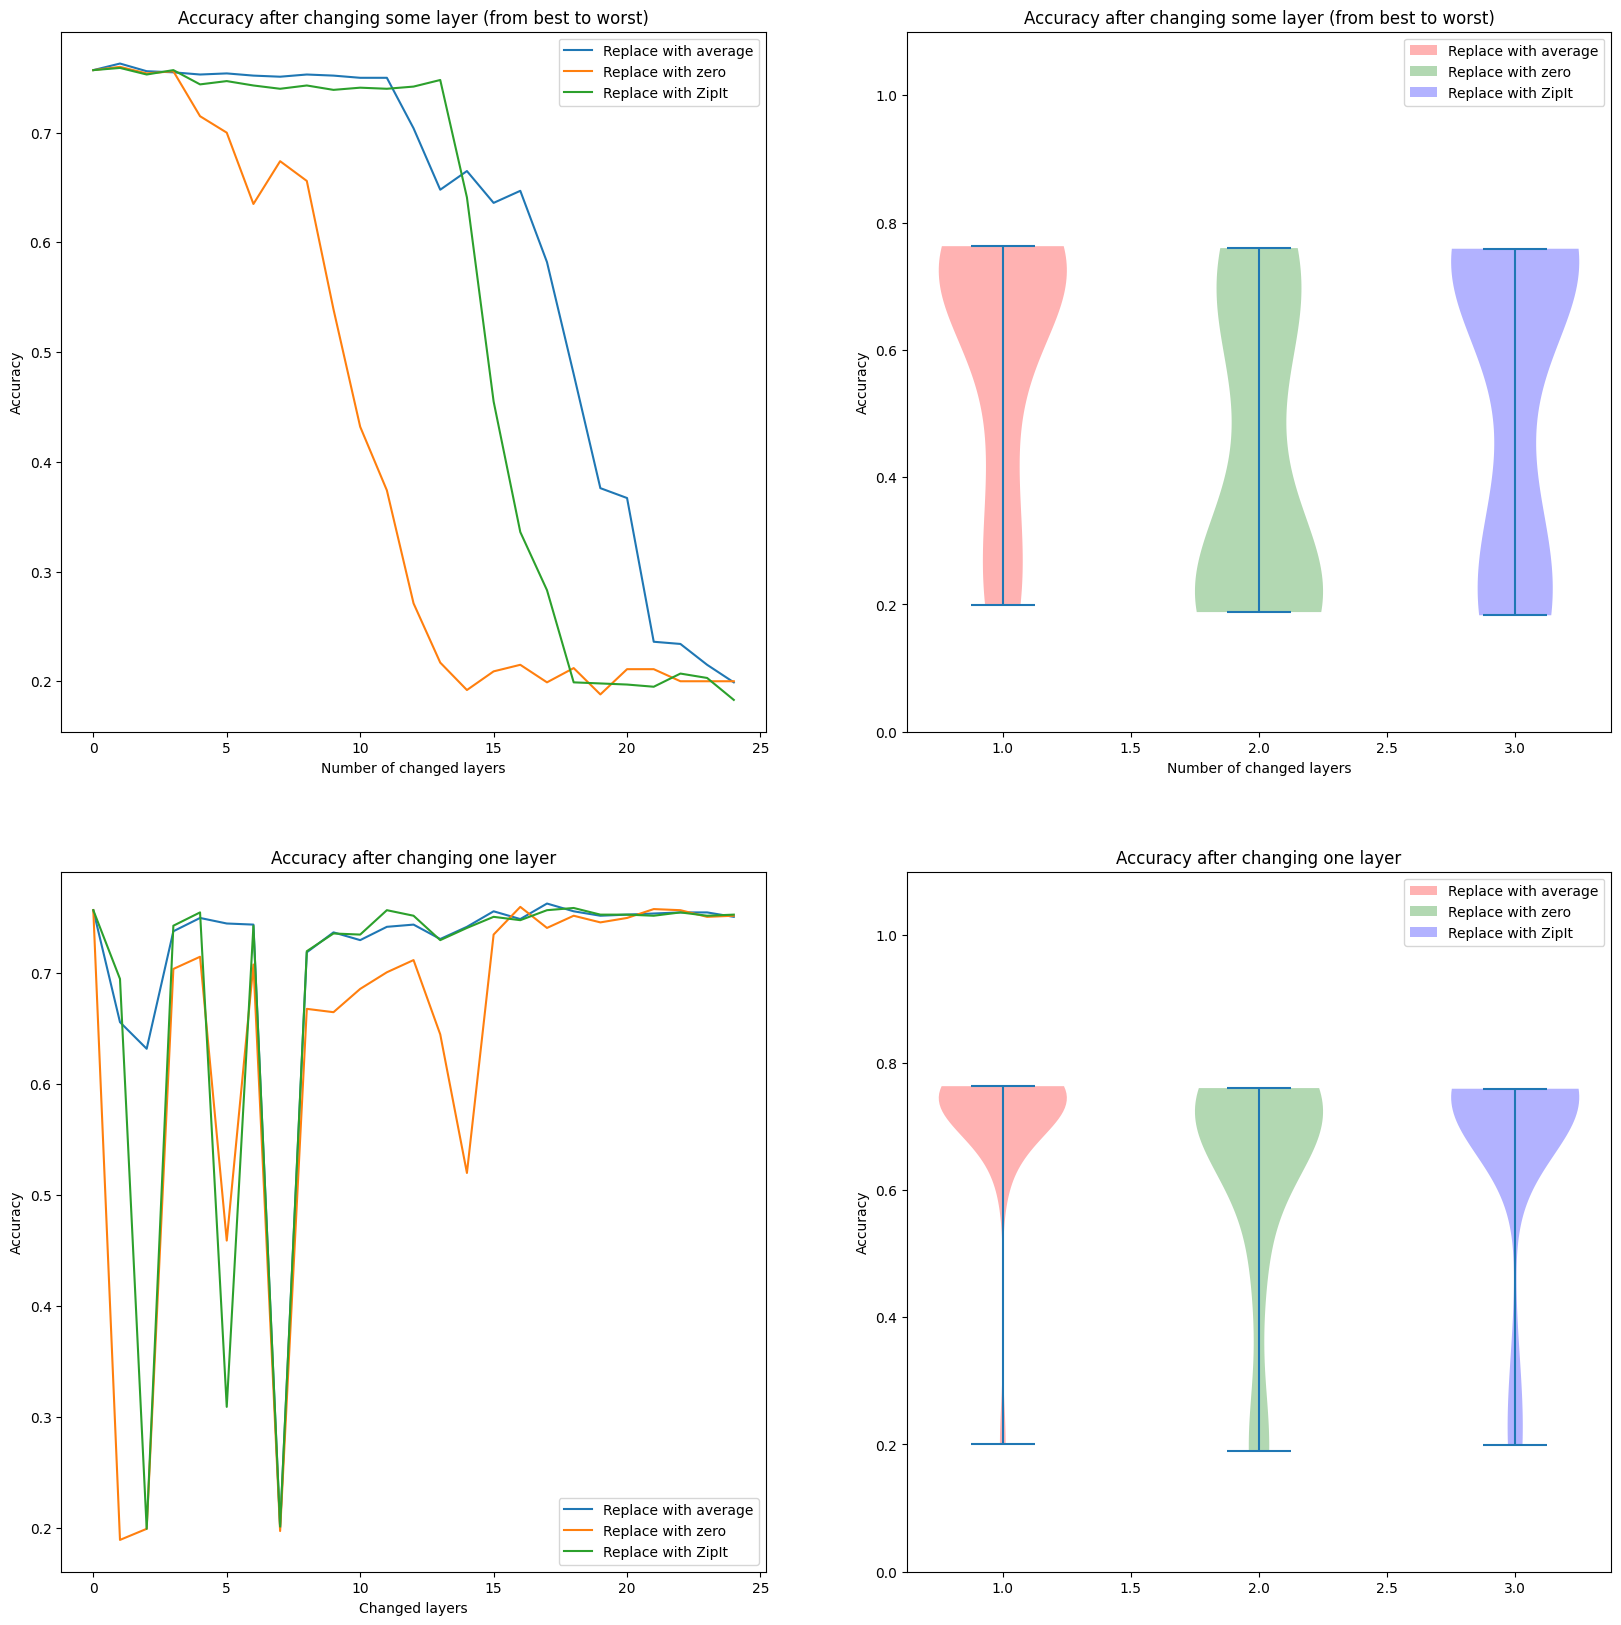

In [6]:
data = {
    "Replace with average": [replace_with_average_seq, replace_with_average_single],
    "Replace with zero": [replace_with_zero_seq, replace_with_zero_single],
    "Replace with ZipIt": [replace_with_zipit_seq, replace_with_zipit_single],
    # "Replace with proj": [replace_with_proj_seq, replace_with_proj_single],
    # "Replace with best": [replace_with_best_seq, replace_with_best_single],
}
draw(data)

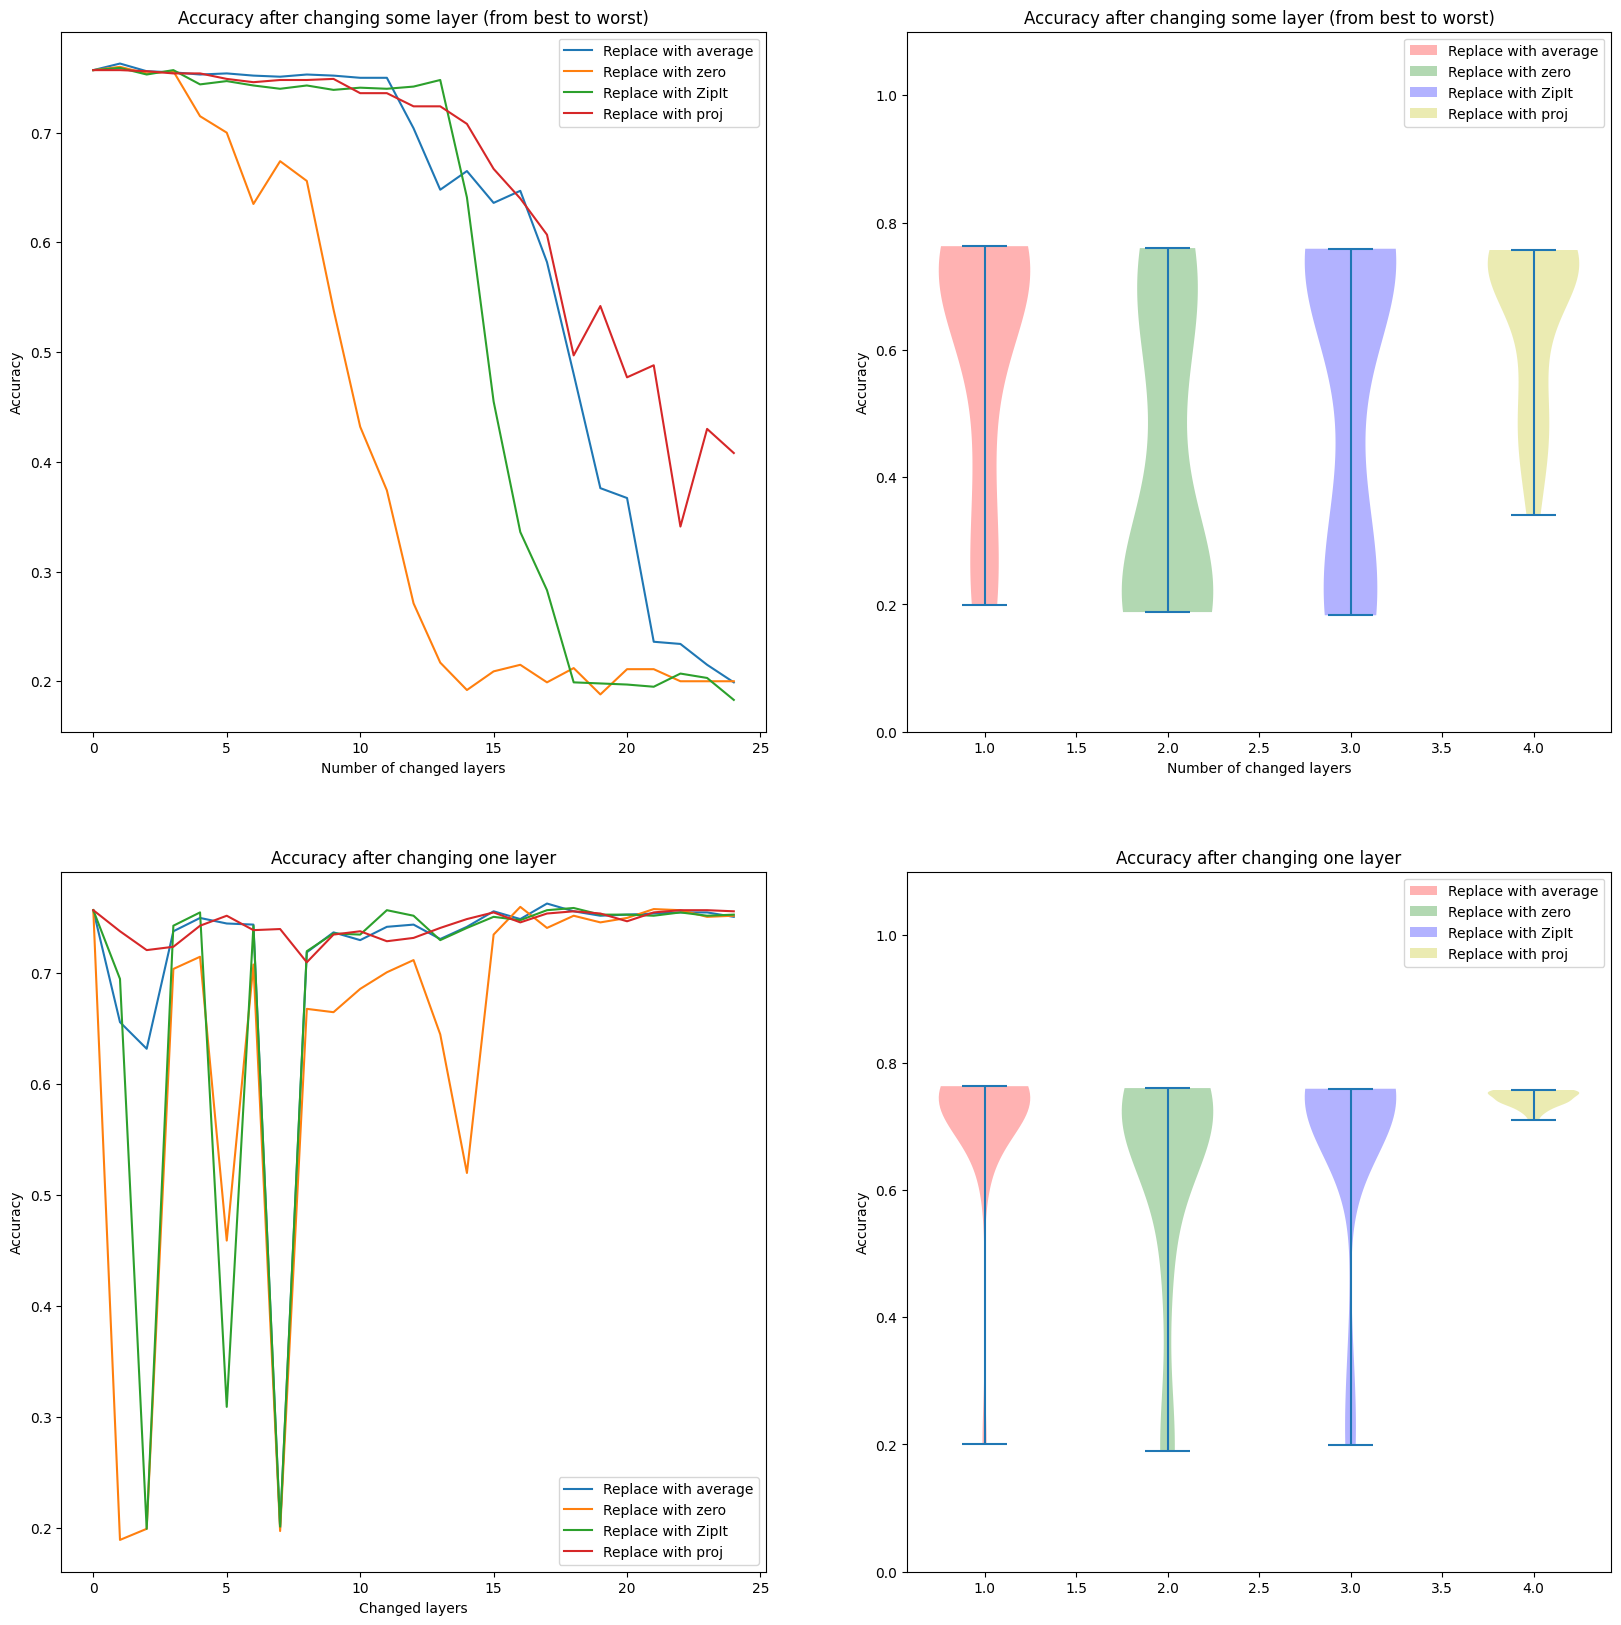

In [7]:
data = {
    "Replace with average": [replace_with_average_seq, replace_with_average_single],
    "Replace with zero": [replace_with_zero_seq, replace_with_zero_single],
    "Replace with ZipIt": [replace_with_zipit_seq, replace_with_zipit_single],
    "Replace with proj": [replace_with_proj_seq, replace_with_proj_single],
    # "Replace with best": [replace_with_best_seq, replace_with_best_single],
}
draw(data)

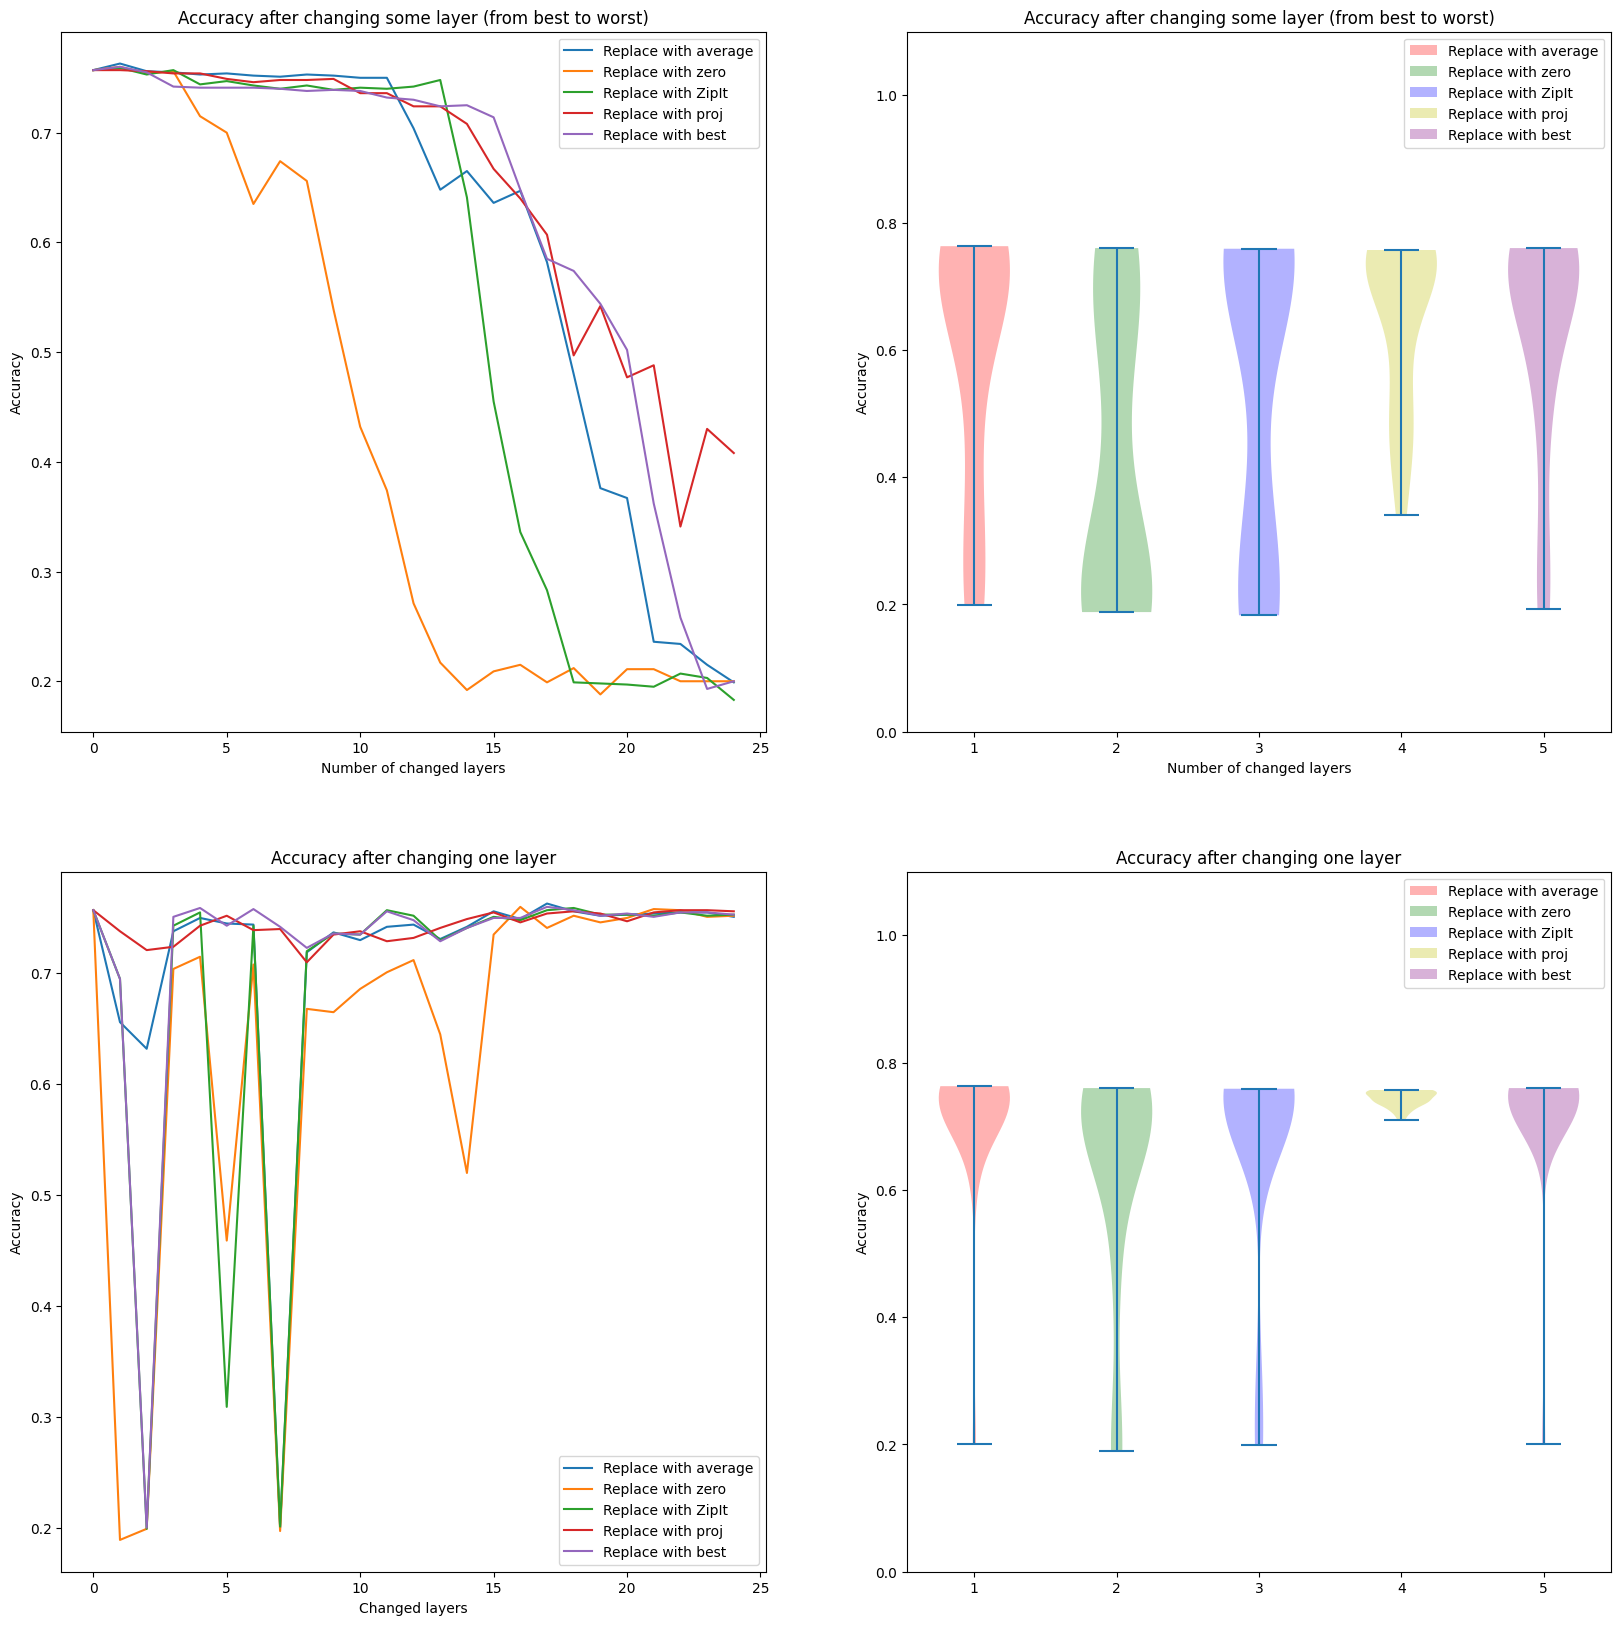

In [8]:
data = {
    "Replace with average": [replace_with_average_seq, replace_with_average_single],
    "Replace with zero": [replace_with_zero_seq, replace_with_zero_single],
    "Replace with ZipIt": [replace_with_zipit_seq, replace_with_zipit_single],
    "Replace with proj": [replace_with_proj_seq, replace_with_proj_single],
    "Replace with best": [replace_with_best_seq, replace_with_best_single],
}
draw(data)

IndexError: list index out of range

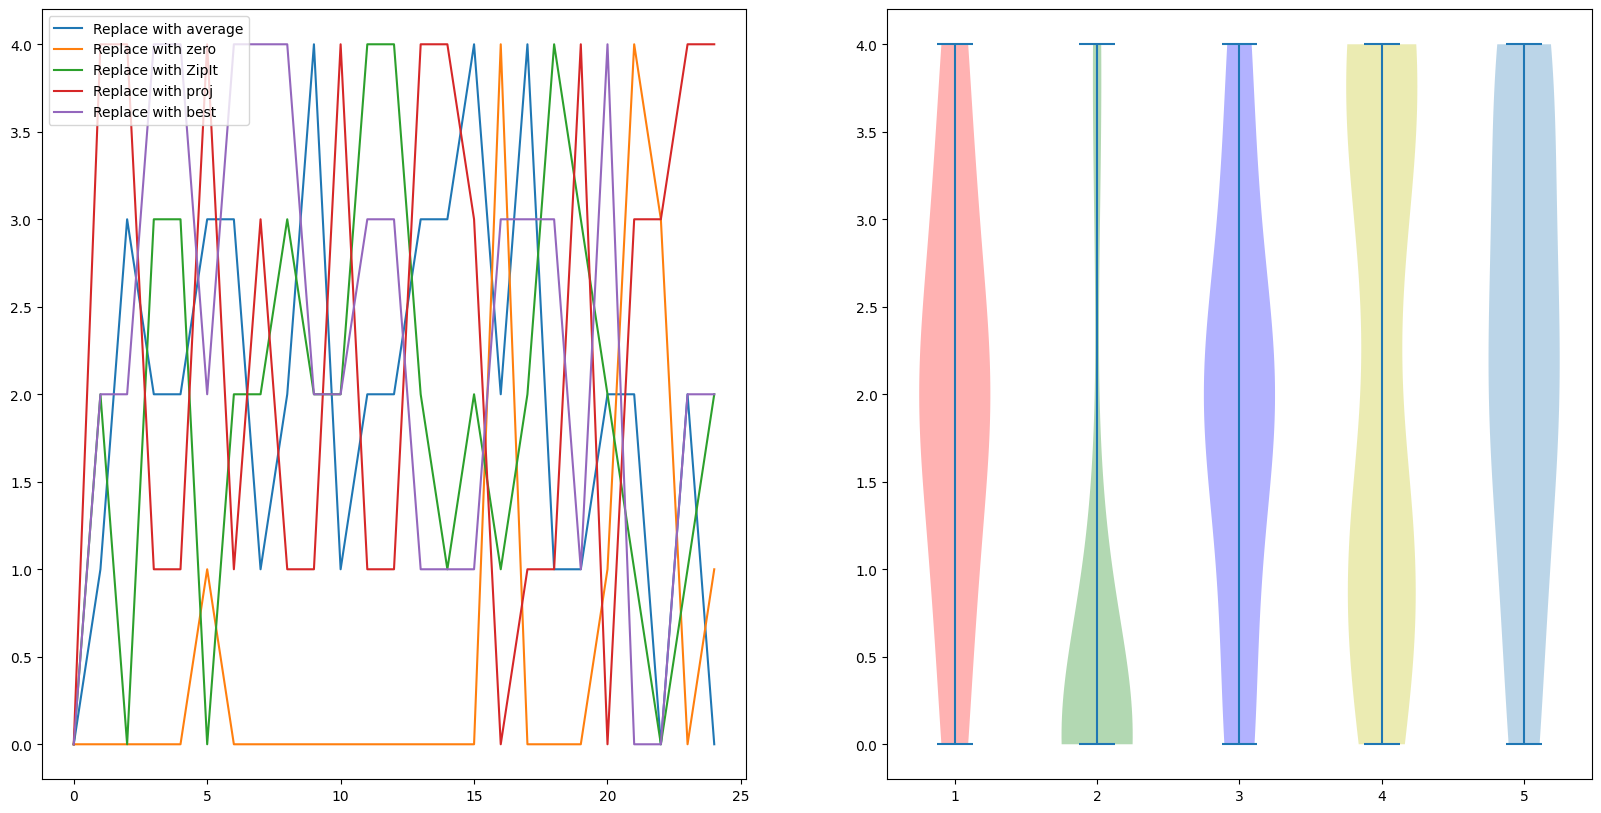

In [9]:
plt.figure(figsize=(20, 10))
data_keys = list(data.keys())
zipped = list(zip(*[data[key][1] for key in data_keys]))
ordered = [[
    sum([zipped[i][k] < zipped[i][j] for k in range(len(zipped[0]))])
for i in range(len(zipped))] for j in range(len(zipped[0]))]

plt.subplot(1, 2, 1)
for i, key in enumerate(data_keys):
    plt.plot(ordered[i], label = key)
plt.legend()

plt.subplot(1, 2, 2)
colors = ['r', 'g', 'b', 'y']
vp = plt.violinplot(ordered)
for i, body in enumerate(vp['bodies']):
    body.set_facecolor(colors[i])
plt.legend(data_keys)
plt.show()

In [ ]:
data = torch.load("logs/fusion/2026_03_30_13X_24_16.pt")
data

In [ ]:
len(data)

In [ ]:
def get_best(results):
    best_key = list(results.keys())[0]
    for key in results.keys():
        if results[key]["MSE"] < results[best_key]["MSE"]:
            best_key = key
    return best_key
best = [get_best(fusion) for fusion in data]
plt.hist(best)
plt.title("Best MSE")

In [ ]:
def get_best(results):
    best_key = list(results.keys())[0]
    for key in results.keys():
        if results[key]["Cosine"] > results[best_key]["Cosine"]:
            best_key = key
    return best_key
best = [get_best(fusion) for fusion in data]
plt.hist(best)
plt.title("Best cosine similarity")

In [ ]:
plt.plot([- result["ZipIt"]["MSE"] + result["Projection"]["MSE"] for result in data])
plt.ylim(-1, 1)

In [ ]:
plt.plot([result["ZipIt"]["Cosine"] - result["Projection"]["Cosine"] for result in data])
plt.ylim(-1, 1)
